# Geomorphic Unit Analysis

In [2]:
import numpy as np
import h5py as h5
import glob
# import cPickle as pickle
import pickle
import scipy

import pandas as pd
# import geopandas as gpd

from datetime import datetime, timedelta
# import geopandas as gpd

import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
# import matplotlib.gridspec as gridspec
import matplotlib.dates as mdates

# import matplotlib.cm as cm
# from matplotlib.colors import LinearSegmentedColormap, Normalize
# from matplotlib.offsetbox import AnchoredOffsetbox, TextArea, HPacker, VPacker
# from matplotlib.colors import LogNorm

from numpy.polynomial.polynomial import polyfit
from scipy import stats
from scipy.stats import pearsonr, spearmanr, mannwhitneyu

from natsort import natsorted

from tqdm.notebook import tqdm
import shapefile
import seaborn as sns
from HFRfunc import *

from hydroeval import *

from mpl_toolkits.axes_grid1.inset_locator import zoomed_inset_axes, mark_inset

from pandas.plotting import register_matplotlib_converters
register_matplotlib_converters()

In [3]:
%matplotlib inline
import matplotlib as mpl
mpl.rcParams['figure.dpi'] = 150

In [4]:
case_name =  "TH_100x100x2_thermal/"
# case_name = "TH_cp_low/"
# case_name =  "TH_100x100x2_thermal_smoothRiver/"
model_dir = "/global/cscratch1/sd/pshuai/" + case_name
out_dir = "/global/project/projectdirs/m1800/pin/HFR-thermal/outputs/" + case_name
results = "/global/project/projectdirs/m1800/pin/HFR-thermal/results/"
result_dir = "/global/project/projectdirs/m1800/pin/HFR-thermal/results/" + case_name
# base_result_dir = "/global/project/projectdirs/m1800/pin/HFR-thermal/results/TH_100x100x2_thermal/"
# base_out_dir = "/global/project/projectdirs/m1800/pin/HFR-thermal/outputs/TH_100x100x2_thermal/"

data_dir = "/global/project/projectdirs/m1800/pin/HFR-thermal/data/"

fname_unique_xy_p = result_dir + "unique_xy_df.p"
fname_temp_data_all_base = result_dir + "temp_data_all_df_5d.p"

fname_temp_data_6h = result_dir + "temp_data_riverbed_6h_2011-2015.p"
fname_all_mass1 = result_dir + "mass1_all_2010_2018.p"
fname_out_flux_6h_base = result_dir + "out_flux_df_6h.p"

fname_riverbed_temp = result_dir + "temp_data_riverbed_6h_2016-2019.p"
fname_pflotran_h5_cont = model_dir + "TH_100x100x2_thermal_new_obs_wells_cont.h5"

fname_GU_shp = data_dir + "geomorphic_unit/RC_wet5_classes.shp"
fname_GU_csv = data_dir + "geomorphic_unit/Reach.scale.classification_wet5_withFacies.csv"

fname_redd_flux_temp = result_dir + 'river_cell_redd_flux_temp_2013.csv'
## riverbed temp
# fname_RG3_T = data_dir + "riverbed_temp_data/RG3_T3/300_Area_RG3_T3_Temps_20180502.csv"
# fname_RG3_T_dat = data_dir + "riverbed_temp_data/RG3_T3/RG3_T3_Temps.dat"
# fname_DA_T = data_dir + "riverbed_temp_data/DenseArray/DA1_CRiver_TM_T.csv"
# fname_100H_dir = data_dir + "riverbed_temp_data/100H_thermistor_rods/"
# iButton_dir = data_dir + 'riverbed_temp_data/iButton/'

## Import temperature data

In [31]:
with open(result_dir + "river_cell_HU_temp.p", "rb") as f:
    river_cell_temp_data = pickle.load(f)

In [4]:
file = open(results + 'unique_river_cells_no_island.txt', "r")  
unique_river_cells_no_island = file.read().split('\n')
unique_river_cells_no_island = [int(i) for i in unique_river_cells_no_island if i != '']

In [6]:
with open(fname_temp_data_all_base, "rb") as f:
    temp_data_all_cells = pickle.load(f)

In [7]:
with open(fname_temp_data_6h, "rb") as f:
    temp_data_riverbed_cells = pickle.load(f)

In [5]:
with open(result_dir + 'temp_data_riverbed_6h_2011-2019.p', "rb") as f:
    temp_data_river_cells = pickle.load(f)

In [6]:
with open(result_dir + 'out_flux_df_6h_2011-2019.p', "rb") as f:
    out_flux_df = pickle.load(f)

out_flux_df = out_flux_df * 24 # convert m3/h to m3/day

In [9]:
with open(result_dir + 'riverbed_cell_flux_temp_seasonality_2011-2019.p', 'rb') as f:
    river_cell_flux_temp_seasonality = pickle.load(f)

## import HU shapefile

In [4]:
# gu_shp = shapefile.Reader(fname_GU_shp) 
# gu_shp = gu_shp.shapes() 
# shpfilePoints = [shape.points for shape in gu_shp]
# gu_polygons = shpfilePoints

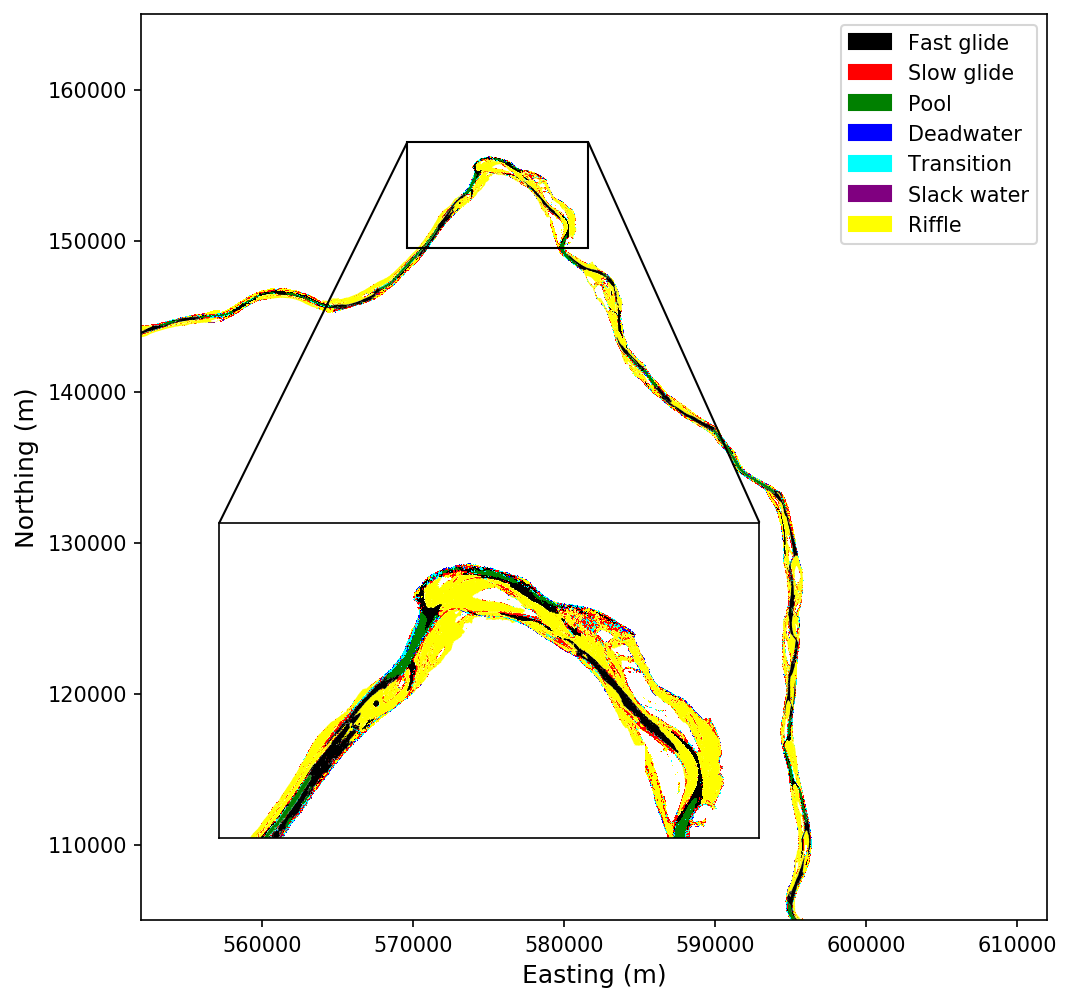

In [188]:
fig, ax = plt.subplots(1,1, figsize=(8,8))
geom_shape=gpd.read_file(fname_GU_shp)

col_list = ['black', 'red', 'green','blue','cyan','purple','yellow', 'none']

colors = [col_list[i] for i in geom_shape['grid_code'].values -1]

geom_shape.plot(facecolor = colors, edgecolor = 'none', ax=ax, alpha=1)

# this is another inset axes over the main axes
a = plt.axes([0.2, 0.1, 0.45, 0.45]) #[x0, y0, len_x, len_y]
geom_shape.plot(facecolor = colors, edgecolor = 'none', ax=a, alpha=1)

a.tick_params(axis = 'both', left=False, top=False, right=False, bottom=False, 
              labelleft=False, labeltop=False, labelright=False, labelbottom=False)
a.set_xlim([569600, 581600])
a.set_ylim([149500, 156500])
a.set_aspect("equal")    
mark_inset(ax, a, loc1=1, loc2=2, fc="none", ec="black")

ax.set_xlim([552000, 612000])
ax.set_ylim([105000, 165000])
ax.set_aspect("equal") 
ax.set_xlabel("Easting (m)", fontsize=12)
ax.set_ylabel("Northing (m)", fontsize=12)

colors = ['black', 'red', 'green','blue','cyan','purple','yellow']
texts = ["Fast glide", "Slow glide", "Pool", "Deadwater", "Transition", "Slack water", "Riffle"]
patches = [ mpatches.Patch(color=colors[i], label="{:s}".format(texts[i]) ) for i in range(len(texts)) ]
ax.legend(handles=patches, bbox_to_anchor=(1, 1), loc='upper right', ncol=1 )

In [189]:
fig.savefig(out_dir + "geomorphology/HU_map.png", dpi=300)
plt.close(fig)

## obtain cell info for each river cell

Remove dupliated columns in `temp_data_all_cells`

In [8]:
with open(result_dir + "cell_df.p", "rb") as f:
    cell_df = pickle.load(f)

In [9]:
with open(fname_unique_xy_p, 'rb') as f:
    unique_xy_df = pickle.load(f)

In [10]:
with open(fname_out_flux_6h_base, "rb") as f:
    out_flux_df = pickle.load(f)

out_flux_df = out_flux_df * 24 # convert m3/h to m3/day

In [27]:
unique_temp_data_all_cells = temp_data_all_cells.loc[:, ~temp_data_all_cells.columns.duplicated()]

In [341]:
hf_id = 1
cell_df = pd.DataFrame(index = unique_river_cells_no_island)
hf_thickness = []
temp_range = []
temp_std = []
flux_range = []
flux_std = []
flux_down_ratio = []
for i_cell in unique_river_cells_no_island[:]:
#     i_cell = 12491565
    i_index = grids[i_cell,]
    # get all cell index below icell
    cells_index = [np.asarray([i_index[0], i_index[1], i_index[2] - i], dtype=int) for i in np.arange(i_index[2]+1)]
    # get depth of each cell
    depth = np.arange(1, 2*len(cells_index) + 1, 2)
    # get all cell ids
    cells_id = [j[0] + j[1]*nx + j[2]*nx*ny for j in cells_index]

    # get material ids for each cell
    cells_material_ids = [material_ids[i] for i in cells_id]
    unique_material_ids = list(set(cells_material_ids))

    #find the thickness for hanford (id = 1)    
    if hf_id in unique_material_ids:
        hf_ind = len(cells_material_ids) - 1 - cells_material_ids[::-1].index(hf_id) # find the last occurance of hf id=1
        hf_depth = depth[hf_ind]
        hf_thickness.append(hf_depth + dz[0]/2)
    else:
        hf_thickness.append(0)

    # find temperature range (max-min)
    col_temp_data = unique_temp_data_all_cells.loc[:, i_cell]
#     col_temp_data = col_temp_data.loc[:, ~col_temp_data.columns.duplicated()].squeeze()
    
    temp_range.append(col_temp_data.max() - col_temp_data.min())
    temp_std.append(col_temp_data.std())

    # find flux range
    iout_flux = out_flux_df.loc[: , i_cell]
    flux_range.append(iout_flux.max() - iout_flux.min())
    flux_std.append(iout_flux.std())

    # find downwelling percentage
    flux_down_ratio.append(len(iout_flux[iout_flux < 0])/len(iout_flux))

cell_df['hf_thickness'] = hf_thickness
cell_df['temp_range'] = temp_range
cell_df['temp_std'] = temp_std
cell_df['flux_range'] = flux_range
cell_df['flux_std'] = flux_std
cell_df['flux_down_ratio'] = flux_down_ratio

In [49]:
temp_min = []
temp_max = []
temp_mean = []
flux_mean = []

for i_cell in cell_df.index[:]:
    col_temp_data = unique_temp_data_all_cells.loc[:, i_cell]
    temp_mean.append(col_temp_data.mean())
    temp_min.append(col_temp_data.min())
    temp_max.append(col_temp_data.max())
    
    iout_flux = out_flux_df.loc[: , i_cell]
    flux_mean.append(iout_flux.mean())

In [50]:
cell_df['temp_mean'] = temp_mean
cell_df['flux_mean'] = flux_mean

cell_df['temp_min'] = temp_min
cell_df['temp_max'] = temp_max

In [55]:
# river_cell_data['temp_mean'] = temp_mean
# river_cell_data['flux_mean'] = flux_mean

river_cell_data['temp_min'] = temp_min
river_cell_data['temp_max'] = temp_max

In [94]:
temp_high_stage = unique_temp_data_all_cells.loc['2011-05-31 12:00:00', cell_df.index]
temp_low_stage = unique_temp_data_all_cells.loc['2011-09-03 12:00:00', cell_df.index]

In [ ]:
temp_high_stage = pd.to_numeric(temp_high_stage)

In [109]:
temp_low_stage = pd.to_numeric(temp_low_stage)

In [110]:
cell_df['temp_2011-05-31'] = temp_high_stage
cell_df['temp_2011-09-03'] = temp_low_stage

In [111]:
river_cell_data['temp_2011-05-31'] = temp_high_stage
river_cell_data['temp_2011-09-03'] = temp_low_stage

In [114]:
with open(result_dir + "cell_df.p", "wb") as f:
    pickle.dump(cell_df, f)

## assign HU to river cells

In [29]:
gu_df = pd.read_csv(fname_GU_csv)

In [46]:
river_cell_data = pd.concat([cell_df, unique_xy_df], axis = 1, join= 'inner' )

**add geomorphic unit id to each river cell**

In [92]:
start = time()
atexit.register(endlog)
log("Start Program")

count= 1
HUid = []
for i in river_cell_data.index[:]:
#     log("progress:{}/{}".format(count, river_cell_data.shape[0]))
    ix = river_cell_data.loc[i, 'x']
    iy = river_cell_data.loc[i, 'y']
    
    x_range = [ix-50, ix + 50]
    y_range = [iy-50, iy + 50]
    
    idf = gu_df[(gu_df['Easting'] >=x_range[0]) & (gu_df['Easting'] <= x_range[1]) & 
                (gu_df['Northing'] >= y_range[0]) & (gu_df['Northing'] <= y_range[1])]
    
    HUid.append(idf.clusterID.value_counts().index[0]) 
    
    count += 1
    
endlog()

2020-01-29 22:01:59 - Start Program

2020-01-29 22:02:41 - End Program
Elapsed time: 0:00:41.522612



In [99]:
river_cell_data['HU_id'] = HUid

river_cell_data.index.name = 'cell_id'

**add geomorphic unit name to river cells**

Note the **fast glide** and **slow glide** were combined into one-- **glide**

In [118]:
HU_name_list = {1:'Glide', 2:'Glide', 3:'Pool', 4:'Deadwater', 5:'Transition', 6:'Slack water', 7:'Riffle'}

HU_name = [HU_name_list[i] for i in river_cell_data.HU_id]

river_cell_data['HU_name'] = HU_name

**add non-hf and hf label to each river cell**

In [129]:
hf_idx = ['Hf' if i == 1 else 'non-Hf' for i in river_cell_data.material_id]

In [130]:
river_cell_data['hf_idx'] = hf_idx

In [116]:
with open(result_dir + "river_cell_HU.p", "wb") as f:
    pickle.dump(river_cell_data, f)

focus on three main HU, i.e., glide, pool and riffle, which accounts for 91.8% of entire reach

In [4]:
with open(result_dir + "river_cell_HU.p", "rb") as f:
    river_cell_data = pickle.load(f)

In [238]:
temp_river_cells_transpose = temp_river_cells.T

In [240]:
river_cell_temp_data = pd.concat([river_cell_data, temp_river_cells_transpose], axis = 1, join= 'inner' )

In [245]:
with open(result_dir + "river_cell_HU_temp.p", "wb") as f:
    pickle.dump(river_cell_temp_data, f)

**regroup geomorphic units into three: Pool, glide, and riffle**

In [228]:
river_cell_data_sub = river_cell_data[(river_cell_data['HU_name'] == 'Pool') | (river_cell_data['HU_name'] == 'Riffle') \
                                     | (river_cell_data['HU_name'] == 'Glide')]

In [21]:
river_cell_temp_data_sub = river_cell_temp_data[(river_cell_temp_data['HU_name'] == 'Pool') | (river_cell_temp_data['HU_name'] == 'Riffle') \
                                     | (river_cell_temp_data['HU_name'] == 'Glide')]

In [257]:
# cols = ['HU_name', 'hf_idx'] + list(river_cell_temp_data_sub.columns[18:])

# river_cell_temp_data_sub = river_cell_temp_data_sub[cols]

## River morphology impact

In [5]:
with open(result_dir + 'riverbed_cell_flux_temp_seasonality_2011-2019.p', 'rb') as f:
    unique_xy_df = pickle.load(f)

In [8]:
df = unique_xy_df.copy()
flow_idx = ['Downwelling dominated' if i <0.5 else 'Upwelling dominated' for i in df.gaining_ratio]
df['flow_idx'] = flow_idx

**seperate downwelling and upwelling dominated areas based on seasons**

In [9]:
flow_idx_winter = ['Downwelling dominated' if i <0.5 else 'Upwelling dominated' for i in df['gaining_ratio_winter']]
flow_idx_spring = ['Downwelling dominated' if i <0.5 else 'Upwelling dominated' for i in df['gaining_ratio_spring']]
flow_idx_summer = ['Downwelling dominated' if i <0.5 else 'Upwelling dominated' for i in df['gaining_ratio_summer']]
flow_idx_fall = ['Downwelling dominated' if i <0.5 else 'Upwelling dominated' for i in df['gaining_ratio_fall']]
df['flow_idx_winter'] = flow_idx_winter
df['flow_idx_spring'] = flow_idx_spring
df['flow_idx_summer'] = flow_idx_summer
df['flow_idx_fall'] = flow_idx_fall

In [7]:
df['placeholder'] = 'placeholder' #need a placeholder for x for a single splitted violin

In [40]:
arr = []
for iseason in ['winter', 'spring', 'summer', 'fall']:
    d1 = np.array(np.unique(df[f'flow_idx_{iseason}'].values, return_counts = True)).transpose()
    d2 = np.array([iseason]*2).reshape(2, 1)
    d3 = np.concatenate((d1, d2), axis = 1)
    arr.append(d3)
df_count = pd.DataFrame(np.vstack(arr), columns=['hue', 'Counts', 'season'])

In [43]:
df_count

,hue,Counts,season
0,Downwelling dominated,1994,winter
1,Upwelling dominated,2841,winter
2,Downwelling dominated,3147,spring
3,Upwelling dominated,1688,spring
4,Downwelling dominated,1037,summer
5,Upwelling dominated,3798,summer
6,Downwelling dominated,300,fall
7,Upwelling dominated,4535,fall


In [61]:
df_idx = df[['flow_idx_winter', 'flow_idx_spring', 'flow_idx_summer', 'flow_idx_fall']]

In [68]:
unique_list = [len(np.unique(df_idx.iloc[i, :])) for i in np.arange(df_idx.shape[0])]

In [74]:
arr = np.array(np.unique(unique_list, return_counts = True)).transpose()
arr

array([[   1, 1915],
       [   2, 2920]])

In [78]:
print(f'{arr[0, 1]/(arr[:, 1].sum())*100}% river cells stay the same upwelling or downwelling condition over a year;\n {arr[1, 1]/(arr[:, 1].sum())*100}% river cells change the dominant flow conditions')

39.60703205791106% river cells stay the same upwelling or downwelling condition over a year;
 60.39296794208894% river cells change the dominant flow conditions


## plot upwelling/downwelling trend over seasons

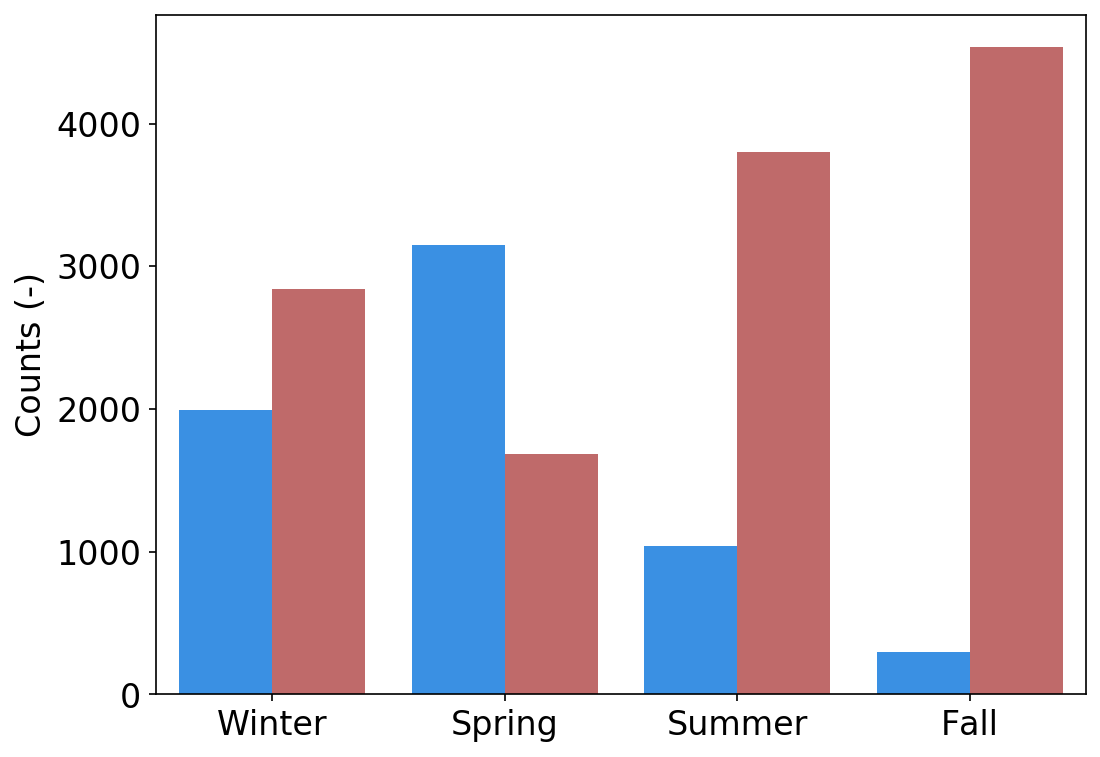

In [52]:
fig, ax = plt.subplots(1,1, figsize=(8,6))
ax = sns.barplot(x= 'season', y = 'Counts', hue = 'hue', data = df_count, 
            palette= {'Upwelling dominated': 'indianred', 'Downwelling dominated':'dodgerblue'})
ax.set_xlabel('')
ax.set_xticklabels(['Winter', 'Spring', 'Summer', 'Fall'])
ax.set_ylabel('Counts (-)', fontsize = 16)
ax.legend(title = '', loc= 'upper left', fontsize = 12)
ax.legend().remove()
ax.tick_params(axis='both', which='major', labelsize=16)

In [53]:
fig.savefig(out_dir + "geomorphology/upwelling_season_counts-noLegend.png", dpi=300)
plt.close(fig)

## HU vs temp

### HU vs all temperature series

In [259]:
# convert df from wide form to long form
river_cell_temp_data_melt = pd.melt(river_cell_temp_data_sub, id_vars=['HU_name', 'hf_idx'], 
        var_name='datetime', value_name='temp')

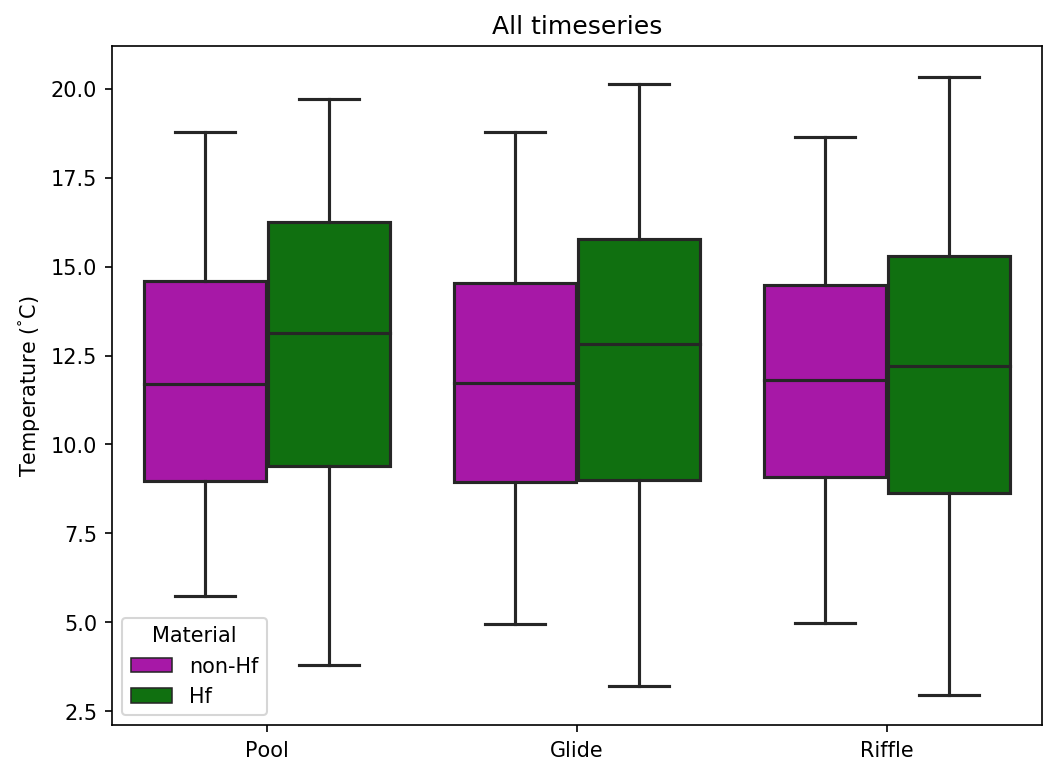

In [262]:
fig, ax = plt.subplots(1,1, figsize=(8,6))

ax = sns.boxplot(x="HU_name", y="temp", hue="hf_idx", palette=["m", "g"], data=river_cell_temp_data_melt)
ax.set_xlabel('')
ax.set_ylabel('Temperature ($^\degree$C)')
ax.set_title('All timeseries', fontsize=12)
ax.legend(title = 'Material')

In [263]:
fig.savefig(out_dir + "geomorphology/T_vs_HU_all_temp_series.png", dpi=300)
plt.close(fig)

### HU vs T std

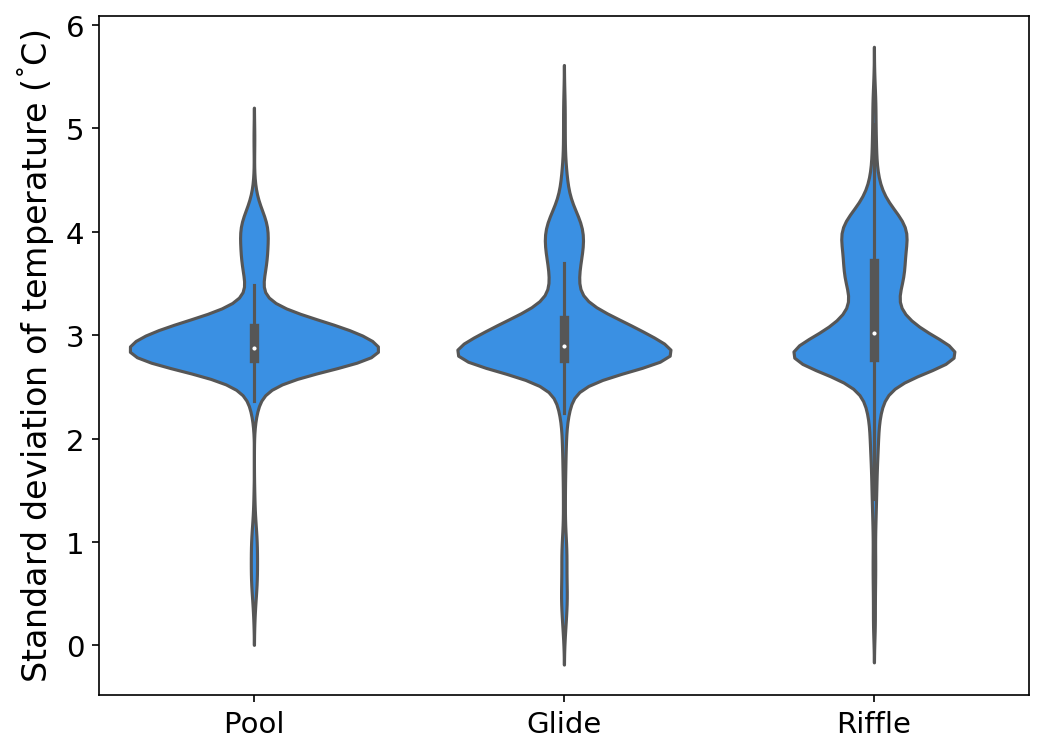

In [23]:
fig, ax = plt.subplots(1,1, figsize=(8,6))

ax = sns.violinplot(x="HU_name", y="temp_std", data=river_cell_temp_data_sub, color = 'dodgerblue')
ax.set_xlabel('')
ax.set_ylabel('Standard deviation of temperature ($^\degree$C)', fontsize = 16)

ax.tick_params(axis='both', which='major', labelsize=14)

In [24]:
fig.savefig(out_dir + "geomorphology/T_std_vs_HU-violin.png", dpi=300)
plt.close(fig)

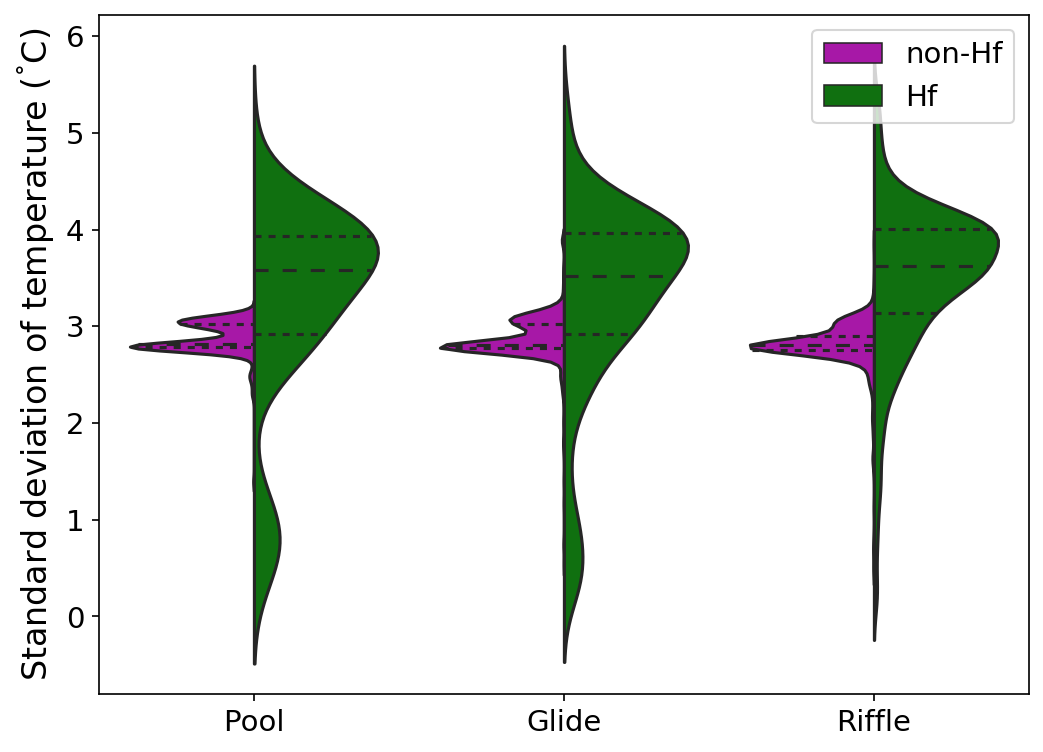

In [45]:
fig, ax = plt.subplots(1,1, figsize=(8,6))

ax = sns.violinplot(x="HU_name", y="temp_std", hue="hf_idx", palette=["m", "g"], 
                    split = True, inner = "quartile", scale = 'width',
                 data=river_cell_temp_data_sub)
ax.legend(title = '', fontsize = 14)
ax.set_xlabel('')
ax.set_ylabel('Standard deviation of temperature ($^\degree$C)', fontsize= 16)
ax.tick_params(axis='both', which='major', labelsize=14)

In [46]:
fig.savefig(out_dir + "geomorphology/T_std_vs_HU_hf-violin.png", dpi=300)
plt.close(fig)

### HU vs mean T

Text(0, 0.5, 'Mean temperature ($^\\degree$C)')

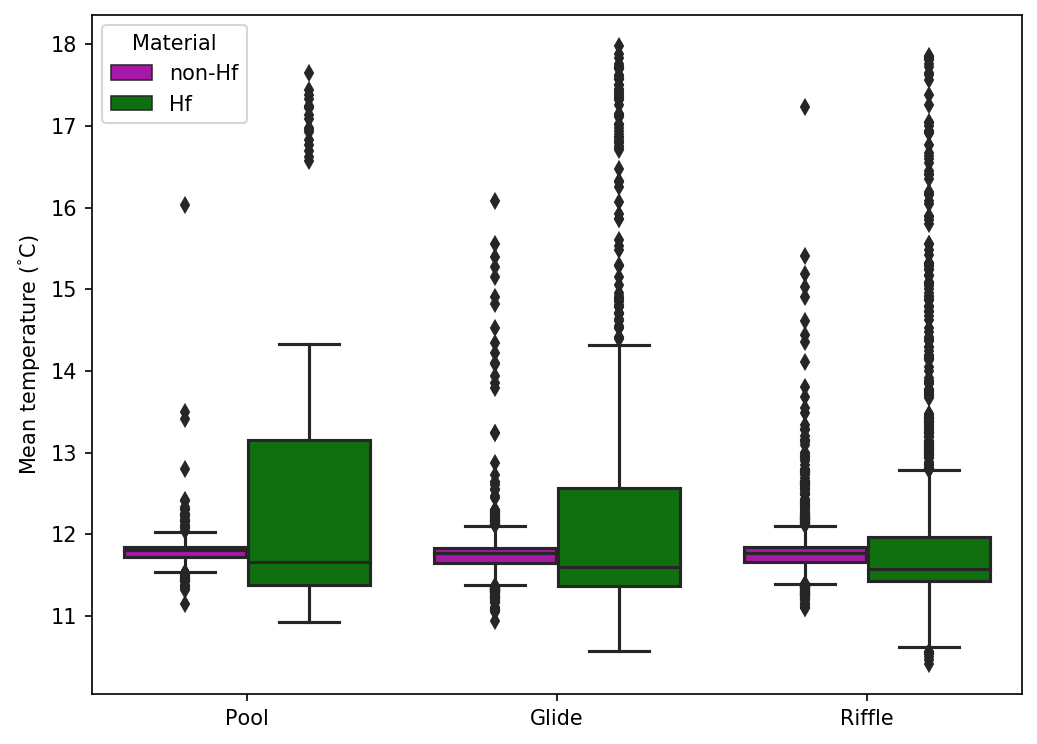

In [45]:
fig, ax = plt.subplots(1,1, figsize=(8,6))

ax = sns.boxplot(x="HU_name", y="temp_mean", hue="hf_idx", palette=["m", "g"], 
                 data=river_cell_data_sub)
ax.legend(title = 'Material')
ax.set_xlabel('')
ax.set_ylabel('Mean temperature ($^\degree$C)')

In [46]:
fig.savefig(out_dir + "geomorphology/T_mean_vs_HU_hf.png", dpi=300)
plt.close(fig)

## HU vs gaining/losing ratio

In [9]:
# unique_xy_df = pd.read_csv(fname_redd_flux_temp, index_col=0)

# unique_xy_no_islands = unique_xy_df.loc[unique_river_cells_no_island, :]

# river_cell_temp_data = pd.concat((river_cell_temp_data, unique_xy_no_islands.gaining_ratio), axis=1)

# with open(result_dir + "river_cell_HU_temp.p", "wb") as f:
#     pickle.dump(river_cell_temp_data, f, protocol=-1)

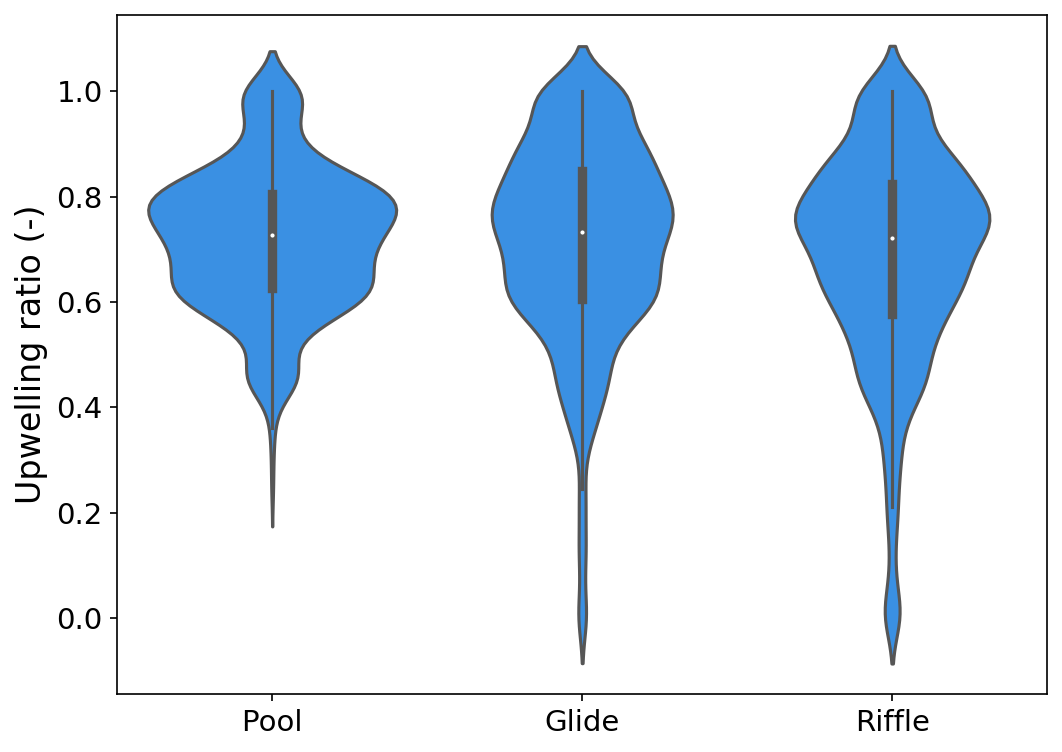

In [29]:
fig, ax = plt.subplots(1,1, figsize=(8,6))
ax = sns.violinplot(x="HU_name", y="gaining_ratio", data=river_cell_temp_data_sub, color = 'dodgerblue')
# ax = sns.boxplot(x="HU_name", y="gaining_ratio", data=river_cell_temp_data_sub, hue="hf_idx", palette=["m", "g"]) 

ax.set_xlabel('')
ax.set_ylabel('Upwelling ratio (-)', fontsize = 16)
ax.tick_params(axis='both', which='major', labelsize=14)

In [30]:
fig.savefig(out_dir + "geomorphology/gaining_ratio_vs_HU-violin.png", dpi=300)
plt.close(fig)

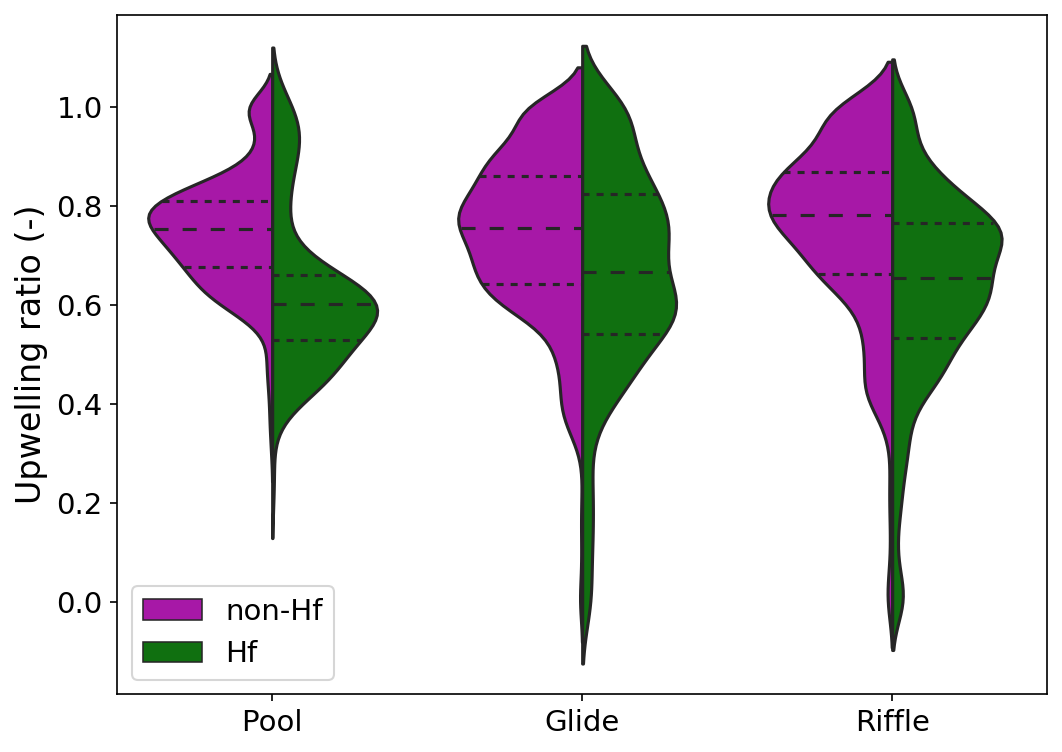

In [37]:
fig, ax = plt.subplots(1,1, figsize=(8,6))

ax = sns.violinplot(x="HU_name", y="gaining_ratio", hue="hf_idx", palette=["m", "g"], 
                    split = True, inner = "quartile",
                 data=river_cell_temp_data_sub)
ax.legend(title = '', loc= 'lower left', fontsize = 14)
ax.set_xlabel('')
ax.set_ylabel('Upwelling ratio (-)', fontsize= 16)
ax.tick_params(axis='both', which='major', labelsize=14)

In [38]:
fig.savefig(out_dir + "geomorphology/gaining_ratio_vs_HU_hf-violin.png", dpi=300)
plt.close(fig)

## HU vs flux

Text(0, 0.5, 'Standard deviation of flux ($m^3/d$)')

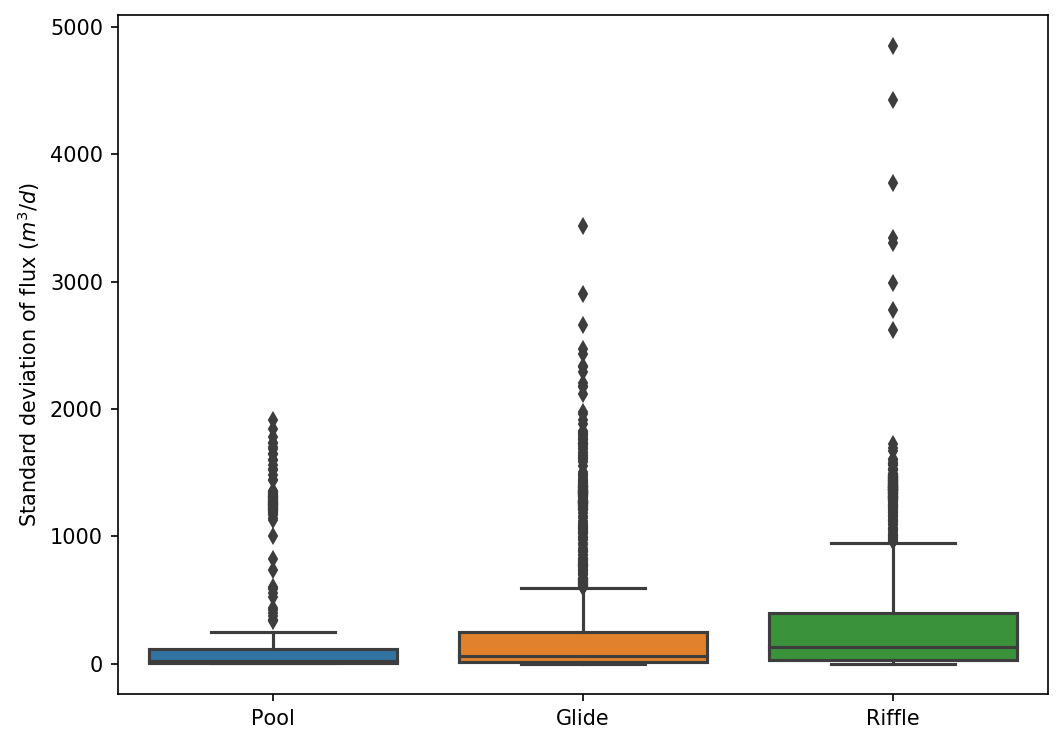

In [19]:
fig, ax = plt.subplots(1,1, figsize=(8,6))
ax = sns.boxplot(x="HU_name", y="flux_std", data=river_cell_data_sub)
ax.set_xlabel('')
ax.set_ylabel('Standard deviation of flux ($m^3/d$)')

In [20]:
fig.savefig(out_dir + "geomorphology/Flux_std_vs_HU.png", dpi=300)
plt.close(fig)

Text(0, 0.5, 'Standard deviation of flux ($m^3/d$)')

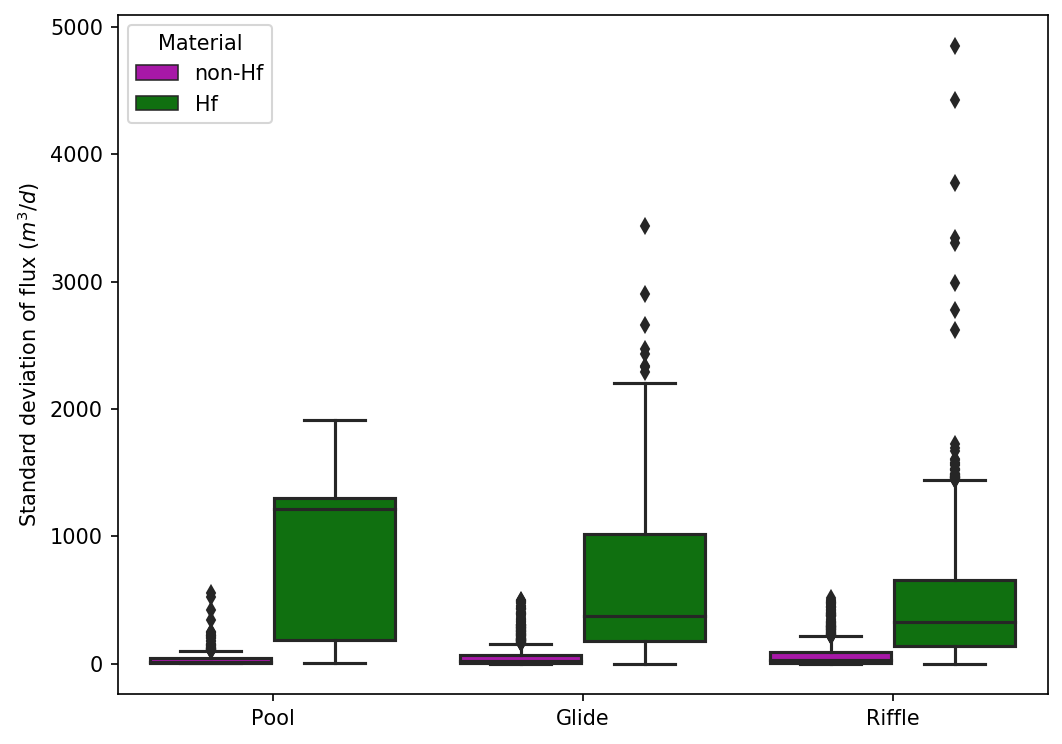

In [22]:
fig, ax = plt.subplots(1,1, figsize=(8,6))

ax = sns.boxplot(x="HU_name", y="flux_std", hue="hf_idx", palette=["m", "g"], 
                 data=river_cell_data_sub)
ax.legend(title = 'Material')
ax.set_xlabel('')
ax.set_ylabel('Standard deviation of flux ($m^3/d$)')

In [23]:
fig.savefig(out_dir + "geomorphology/Flux_std_vs_HU_hf.png", dpi=300)
plt.close(fig)

Text(0, 0.5, 'Mean flux ($m^3/d$)')

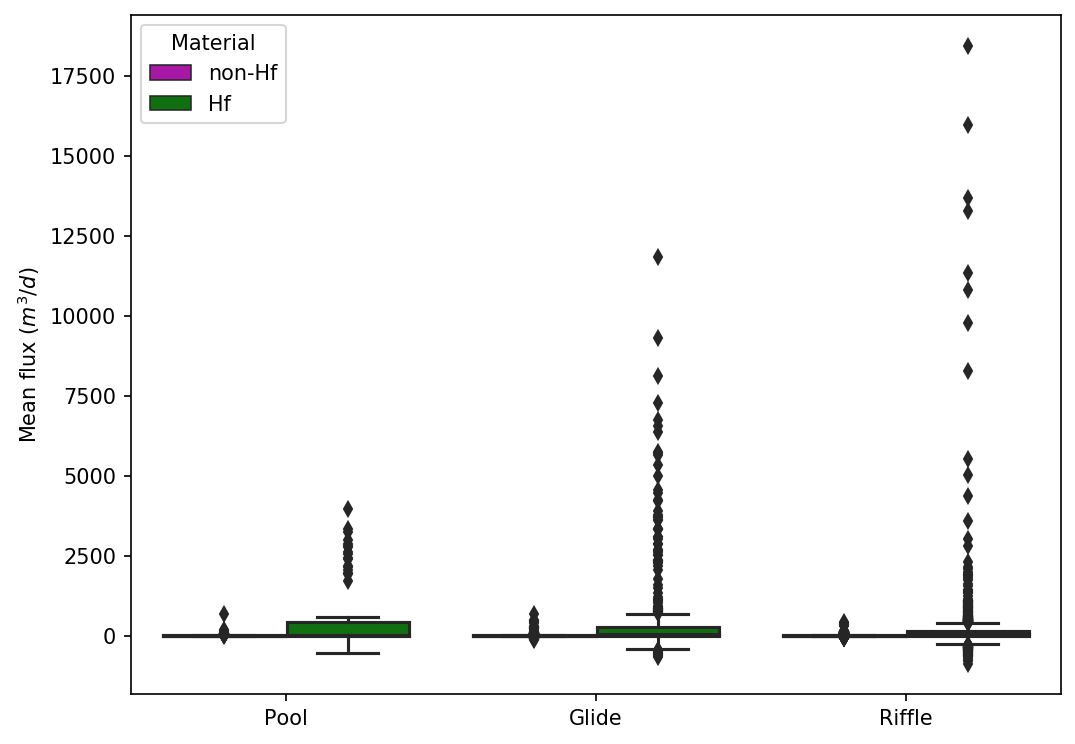

In [47]:
fig, ax = plt.subplots(1,1, figsize=(8,6))

ax = sns.boxplot(x="HU_name", y="flux_mean", hue="hf_idx", palette=["m", "g"], 
                 data=river_cell_data_sub)
ax.legend(title = 'Material')
ax.set_xlabel('')
ax.set_ylabel('Mean flux ($m^3/d$)')

In [48]:
fig.savefig(out_dir + "geomorphology/Flux_mean_vs_HU_hf.png", dpi=300)
plt.close(fig)

In [5]:
with open(result_dir + 'riverbed_cell_flux_temp_seasonality_2011-2019.p', 'rb') as f:
    unique_xy_df = pickle.load(f)

In [8]:
df = unique_xy_df.copy()
flow_idx = ['Downwelling dominated' if i <0.5 else 'Upwelling dominated' for i in df.gaining_ratio]
df['flow_idx'] = flow_idx

**seperate downwelling and upwelling dominated areas based on seasons**

In [9]:
flow_idx_winter = ['Downwelling dominated' if i <0.5 else 'Upwelling dominated' for i in df['gaining_ratio_winter']]
flow_idx_spring = ['Downwelling dominated' if i <0.5 else 'Upwelling dominated' for i in df['gaining_ratio_spring']]
flow_idx_summer = ['Downwelling dominated' if i <0.5 else 'Upwelling dominated' for i in df['gaining_ratio_summer']]
flow_idx_fall = ['Downwelling dominated' if i <0.5 else 'Upwelling dominated' for i in df['gaining_ratio_fall']]
df['flow_idx_winter'] = flow_idx_winter
df['flow_idx_spring'] = flow_idx_spring
df['flow_idx_summer'] = flow_idx_summer
df['flow_idx_fall'] = flow_idx_fall

In [7]:
df['placeholder'] = 'placeholder' #need a placeholder for x for a single splitted violin

In [40]:
arr = []
for iseason in ['winter', 'spring', 'summer', 'fall']:
    d1 = np.array(np.unique(df[f'flow_idx_{iseason}'].values, return_counts = True)).transpose()
    d2 = np.array([iseason]*2).reshape(2, 1)
    d3 = np.concatenate((d1, d2), axis = 1)
    arr.append(d3)
df_count = pd.DataFrame(np.vstack(arr), columns=['hue', 'Counts', 'season'])

In [43]:
df_count

,hue,Counts,season
0,Downwelling dominated,1994,winter
1,Upwelling dominated,2841,winter
2,Downwelling dominated,3147,spring
3,Upwelling dominated,1688,spring
4,Downwelling dominated,1037,summer
5,Upwelling dominated,3798,summer
6,Downwelling dominated,300,fall
7,Upwelling dominated,4535,fall


In [61]:
df_idx = df[['flow_idx_winter', 'flow_idx_spring', 'flow_idx_summer', 'flow_idx_fall']]

In [68]:
unique_list = [len(np.unique(df_idx.iloc[i, :])) for i in np.arange(df_idx.shape[0])]

In [74]:
arr = np.array(np.unique(unique_list, return_counts = True)).transpose()
arr

array([[   1, 1915],
       [   2, 2920]])

In [78]:
print(f'{arr[0, 1]/(arr[:, 1].sum())*100}% river cells stay the same upwelling or downwelling condition over a year;\n {arr[1, 1]/(arr[:, 1].sum())*100}% river cells change the dominant flow conditions')

39.60703205791106% river cells stay the same upwelling or downwelling condition over a year;
 60.39296794208894% river cells change the dominant flow conditions


### plot upwelling/downwelling trend over seasons

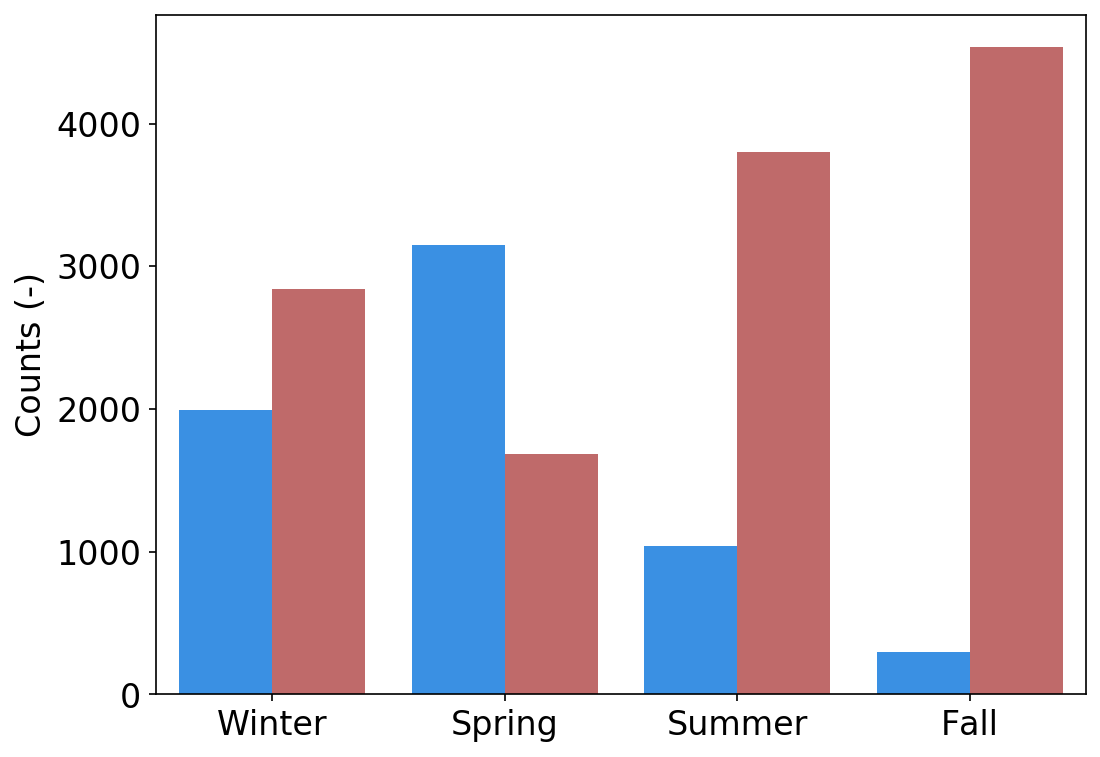

In [52]:
fig, ax = plt.subplots(1,1, figsize=(8,6))
ax = sns.barplot(x= 'season', y = 'Counts', hue = 'hue', data = df_count, 
            palette= {'Upwelling dominated': 'indianred', 'Downwelling dominated':'dodgerblue'})
ax.set_xlabel('')
ax.set_xticklabels(['Winter', 'Spring', 'Summer', 'Fall'])
ax.set_ylabel('Counts (-)', fontsize = 16)
ax.legend(title = '', loc= 'upper left', fontsize = 12)
ax.legend().remove()
ax.tick_params(axis='both', which='major', labelsize=16)

In [53]:
fig.savefig(out_dir + "geomorphology/upwelling_season_counts-noLegend.png", dpi=300)
plt.close(fig)

In [9]:
# with open(result_dir + "river_cell_HU_temp.p", "rb") as f:
#     river_cell_temp_data = pickle.load(f)

In [18]:
# flow_idx = ['Downwelling dominated' if i >0.5 else 'Upwelling dominated' for i in river_cell_temp_data.flux_down_ratio]

# river_cell_temp_data['flow_idx'] = flow_idx